In [51]:
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import re
import time
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# Simple whitespace + punctuation tokenizer (no external NLP
# libraries used, to keep preprocessing fully transparent).
def simple_tokenize(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)       
    text = re.sub(r"[^a-z0-9\s']", " ", text) 
    tokens = text.split()
    return tokens


def build_vocab(list_of_texts, max_vocab_size=20000, min_freq=2):
    """
    Build a word -> index vocabulary from a list of raw text strings.
    Reserves index 0 for <PAD> and index 1 for <UNK>.
    """
    from collections import Counter
    counter = Counter()
    for text in list_of_texts:
        counter.update(simple_tokenize(text))

    # keep only words that appear at least `min_freq` times, most common first
    most_common = [w for w, c in counter.most_common() if c >= min_freq]
    most_common = most_common[:max_vocab_size - 2]  # reserve 2 slots for PAD/UNK

    vocab = {"<PAD>": 0, "<UNK>": 1}
    for i, word in enumerate(most_common, start=2):
        vocab[word] = i
    return vocab


def encode_and_pad(text, vocab, max_len):
    """Convert raw text into a fixed-length list of token indices."""
    tokens = simple_tokenize(text)
    ids = [vocab.get(tok, vocab["<UNK>"]) for tok in tokens]
    if len(ids) < max_len:
        ids = ids + [vocab["<PAD>"]] * (max_len - len(ids))
    else:
        ids = ids[:max_len]
    return ids

Using device: cuda


In [14]:
# quick sanity check on the tokenizer + vocab pipeline
sample_texts = [
    "This movie was absolutely wonderful, I loved it!",
    "Terrible film. Waste of time. Bad acting.",
    "The movie was okay, not great but not terrible either."
]

vocab = build_vocab(sample_texts, min_freq=1)
print("vocab size:", len(vocab))
print("sample vocab entries:", list(vocab.items())[:10])

encoded = encode_and_pad(sample_texts[0], vocab, max_len=12)
print("encoded + padded:", encoded)

vocab size: 23
sample vocab entries: [('<PAD>', 0), ('<UNK>', 1), ('movie', 2), ('was', 3), ('terrible', 4), ('not', 5), ('this', 6), ('absolutely', 7), ('wonderful', 8), ('i', 9)]
encoded + padded: [6, 2, 3, 7, 8, 9, 10, 11, 0, 0, 0, 0]


In [15]:
import os
import tarfile
from tensorflow.keras.utils import get_file

# ============================================================
# Download and extract the raw aclImdb dataset (Maas et al., 2011)
# ============================================================
dataset_url = "http://ai.stanford.edu/~amaas/data/sentiment/aclImdb_v1.tar.gz"
archive_path = get_file("aclImdb_v1.tar.gz", origin=dataset_url, extract=False)

extract_dir = os.path.join(os.path.dirname(archive_path), "aclImdb")
if not os.path.exists(extract_dir):
    with tarfile.open(archive_path) as tar:
        tar.extractall(path=os.path.dirname(archive_path))

data_root = extract_dir
print("Dataset extracted to:", data_root)
print("Contents:", os.listdir(data_root))

Dataset extracted to: C:\Users\84447\.keras\datasets\aclImdb
Contents: ['imdb.vocab', 'imdbEr.txt', 'README', 'test', 'train']


In [16]:
def load_imdb_split(root, split):
    """
    Reads raw review .txt files from aclImdb/<split>/pos and
    aclImdb/<split>/neg, returns (texts, labels).
    label: 1 = positive, 0 = negative
    """
    texts, labels = [], []
    for label_name, label_value in [("pos", 1), ("neg", 0)]:
        folder = os.path.join(root, split, label_name)
        for fname in os.listdir(folder):
            if fname.endswith(".txt"):
                with open(os.path.join(folder, fname), encoding="utf-8") as f:
                    texts.append(f.read())
                labels.append(label_value)
    return texts, labels


train_texts_all, train_labels_all = load_imdb_split(data_root, "train")
test_texts, test_labels = load_imdb_split(data_root, "test")

print(f"Full training set: {len(train_texts_all)} reviews")
print(f"Test set: {len(test_texts)} reviews")
print("Example review:", train_texts_all[0][:200], "...")
print("Example label:", train_labels_all[0])

Full training set: 25000 reviews
Test set: 25000 reviews
Example review: Bromwell High is a cartoon comedy. It ran at the same time as some other programs about school life, such as "Teachers". My 35 years in the teaching profession lead me to believe that Bromwell High's  ...
Example label: 1


In [50]:
# ============================================================
# Split the official 25,000 training reviews into a 50% train /
# 50% validation subset (as required by the brief). The official
# 25,000-review test set is kept untouched for final evaluation.
# ============================================================
np.random.seed(42)
perm = np.random.permutation(len(train_texts_all))
split_point = len(train_texts_all) // 2  # 50/50 split

train_idx = perm[:split_point]
val_idx = perm[split_point:]

train_texts = [train_texts_all[i] for i in train_idx]
train_labels = [train_labels_all[i] for i in train_idx]
val_texts = [train_texts_all[i] for i in val_idx]
val_labels = [train_labels_all[i] for i in val_idx]

print(f"Train subset: {len(train_texts)} reviews")
print(f"Validation subset: {len(val_texts)} reviews")
print(f"Test set (untouched): {len(test_texts)} reviews")

Train subset: 12500 reviews
Validation subset: 12500 reviews
Test set (untouched): 25000 reviews


In [84]:
# ============================================================
# Build vocabulary from the TRAINING subset only (never from
# validation/test — that would leak information about the
# evaluation data into preprocessing).
# ============================================================
MAX_VOCAB_SIZE = 20000
MAX_LEN = 250  # reviews longer than this are truncated, shorter ones padded

vocab = build_vocab(train_texts, max_vocab_size=MAX_VOCAB_SIZE, min_freq=2)
print("Vocabulary size:", len(vocab))

def encode_dataset(texts, labels, vocab, max_len):
    X = np.array([encode_and_pad(t, vocab, max_len) for t in texts], dtype=np.int64)
    y = np.array(labels, dtype=np.float32)
    return X, y

X_train, y_train = encode_dataset(train_texts, train_labels, vocab, MAX_LEN)
X_val, y_val = encode_dataset(val_texts, val_labels, vocab, MAX_LEN)
X_test, y_test = encode_dataset(test_texts, test_labels, vocab, MAX_LEN)

print("X_train shape:", X_train.shape)
print("X_val shape:", X_val.shape)
print("X_test shape:", X_test.shape)
print("Sample encoded review:", X_train[0][:20], "...")

Vocabulary size: 20000
X_train shape: (12500, 250)
X_val shape: (12500, 250)
X_test shape: (25000, 250)
Sample encoded review: [   8 3796    8    2 1996  726 3183  305 1205  421 2959 1064   34   45
   23 1282    1 8009   16    4] ...


In [19]:
class IMDbDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.long)
        self.y = torch.tensor(y, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


BATCH_SIZE = 32

train_dataset = IMDbDataset(X_train, y_train)
val_dataset = IMDbDataset(X_val, y_val)
test_dataset = IMDbDataset(X_test, y_test)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("Number of training batches:", len(train_loader))
print("Number of validation batches:", len(val_loader))
print("Number of test batches:", len(test_loader))

# quick check: pull one batch and inspect its shape
xb, yb = next(iter(train_loader))
print("batch X shape:", xb.shape, "| batch y shape:", yb.shape)
print("batch X dtype:", xb.dtype, "| batch y dtype:", yb.dtype)

Number of training batches: 391
Number of validation batches: 391
Number of test batches: 782
batch X shape: torch.Size([32, 200]) | batch y shape: torch.Size([32])
batch X dtype: torch.int64 | batch y dtype: torch.float32


In [20]:
class PositionalEncoding(nn.Module):
    """
    Classic sinusoidal positional encoding (Vaswani et al., 2017).
    Self-attention has no built-in notion of word order (it treats the
    input as a "bag" of positions), so we inject position information
    by adding a fixed sinusoidal pattern to each token's embedding.
    """

    def __init__(self, d_model, max_len=200):
        super().__init__()

        pe = torch.zeros(max_len, d_model)
        position = torch.arange(0, max_len, dtype=torch.float32).unsqueeze(1)  # (max_len, 1)

        # div_term controls the frequency of the sine/cosine waves at each dimension
        div_term = torch.exp(
            torch.arange(0, d_model, 2, dtype=torch.float32) * (-np.log(10000.0) / d_model)
        )

        pe[:, 0::2] = torch.sin(position * div_term)  # even dimensions -> sine
        pe[:, 1::2] = torch.cos(position * div_term)  # odd dimensions  -> cosine

        pe = pe.unsqueeze(0)  # (1, max_len, d_model), so it broadcasts over the batch dim
        self.register_buffer("pe", pe)  # not a trainable parameter, but moves with .to(device)

    def forward(self, x):
        # x: (N, T, d_model)
        seq_len = x.size(1)
        return x + self.pe[:, :seq_len, :]

In [21]:
# quick sanity check: confirm shape is unchanged and values actually differ by position
pos_enc_test = PositionalEncoding(d_model=64, max_len=200).to(device)
fake_embeddings = torch.zeros(2, 200, 64).to(device)  # 2 fake sentences, all-zero embeddings
out = pos_enc_test(fake_embeddings)

print("output shape:", out.shape)  # expect (2, 200, 64)
print("position 0 vector (first 6 values):", out[0, 0, :6])
print("position 1 vector (first 6 values):", out[0, 1, :6])
# the two rows above should be DIFFERENT -- that's the whole point of positional encoding

output shape: torch.Size([2, 200, 64])
tensor([0., 1., 0., 1., 0., 1.], device='cuda:0')
tensor([0.8415, 0.5403, 0.6816, 0.7318, 0.5332, 0.8460], device='cuda:0')


In [41]:
class MultiHeadSelfAttention(nn.Module):
    """
    Implements scaled dot-product attention and multi-head attention
    from scratch (no nn.MultiheadAttention used).
    """

    def __init__(self, d_model, num_heads):
        super().__init__()
        assert d_model % num_heads == 0, "d_model must be divisible by num_heads"

        self.d_model = d_model
        self.num_heads = num_heads
        self.d_k = d_model // num_heads  # dimension per head

        # Q, K, V projections -- one big Linear layer each, later split into heads
        self.W_q = nn.Linear(d_model, d_model)
        self.W_k = nn.Linear(d_model, d_model)
        self.W_v = nn.Linear(d_model, d_model)

        # output projection, applied after concatenating all heads back together
        self.W_o = nn.Linear(d_model, d_model)

    def split_heads(self, x):
        # x: (N, T, d_model) -> (N, num_heads, T, d_k)
        N, T, _ = x.shape
        x = x.view(N, T, self.num_heads, self.d_k)
        return x.transpose(1, 2)

    def forward(self, x, mask=None):
        # x: (N, T, d_model)
        N, T, _ = x.shape

        Q = self.split_heads(self.W_q(x))  # (N, heads, T, d_k)
        K = self.split_heads(self.W_k(x))
        V = self.split_heads(self.W_v(x))

        # scaled dot-product attention: softmax(QK^T / sqrt(d_k)) V
        scores = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(self.d_k)  # (N, heads, T, T)

        if mask is not None:
            # mask: (N, 1, 1, T) -- True/1 where the token is real, False/0 where it's padding
            scores = scores.masked_fill(mask == 0, float("-1e9"))

        attn_weights = F.softmax(scores, dim=-1)  # (N, heads, T, T)
        attn_output = torch.matmul(attn_weights, V)  # (N, heads, T, d_k)

        # merge heads back: (N, heads, T, d_k) -> (N, T, d_model)
        attn_output = attn_output.transpose(1, 2).contiguous().view(N, T, self.d_model)

        return self.W_o(attn_output), attn_weights

In [23]:
# quick sanity check: shapes, and confirm each attention row sums to 1
mha_test = MultiHeadSelfAttention(d_model=64, num_heads=4).to(device)
fake_x = torch.rand(2, 200, 64).to(device)  # 2 fake sentences, seq_len=200, d_model=64

out, attn_weights = mha_test(fake_x)
print("output shape:", out.shape)              # expect (2, 200, 64) -- same shape as input
print("attention weights shape:", attn_weights.shape)  # expect (2, 4, 200, 200)
print("attention row sums (should be ~1.0):", attn_weights[0, 0, 0, :].sum().item())

output shape: torch.Size([2, 200, 64])
attention weights shape: torch.Size([2, 4, 200, 200])
attention row sums (should be ~1.0): 1.0


In [24]:
class FeedForward(nn.Module):
    """Two-layer feedforward network with ReLU, applied to each position independently."""

    def __init__(self, d_model, d_ff, dropout=0.1):
        super().__init__()
        self.fc1 = nn.Linear(d_model, d_ff)
        self.fc2 = nn.Linear(d_ff, d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        return self.fc2(self.dropout(F.relu(self.fc1(x))))


class TransformerEncoderBlock(nn.Module):
    """
    One Transformer encoder block:
        x -> MultiHeadSelfAttention -> Add & LayerNorm -> FeedForward -> Add & LayerNorm
    Residual ("Add") connections + LayerNorm are standard Transformer
    design choices that make deep stacks of these blocks trainable.
    """

    def __init__(self, d_model, num_heads, d_ff, dropout=0.1):
        super().__init__()
        self.attn = MultiHeadSelfAttention(d_model, num_heads)
        self.ff = FeedForward(d_model, d_ff, dropout)

        self.norm1 = nn.LayerNorm(d_model)
        self.norm2 = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, mask=None):
        # --- sub-layer 1: self-attention, with residual connection ---
        attn_out, attn_weights = self.attn(x, mask)
        x = self.norm1(x + self.dropout(attn_out))  # residual connection + LayerNorm

        # --- sub-layer 2: feedforward, with residual connection ---
        ff_out = self.ff(x)
        x = self.norm2(x + self.dropout(ff_out))  # residual connection + LayerNorm

        return x, attn_weights


def make_padding_mask(x, pad_idx=0):
    """
    x: (N, T) token id sequences.
    Returns mask of shape (N, 1, 1, T): 1 where token is real, 0 where it's <PAD>.
    Shaped to broadcast directly against attention scores (N, heads, T, T).
    """
    mask = (x != pad_idx).unsqueeze(1).unsqueeze(2)  # (N, 1, 1, T)
    return mask

In [25]:
# quick sanity check: full encoder block + padding mask
block_test = TransformerEncoderBlock(d_model=64, num_heads=4, d_ff=128).to(device)

fake_x = torch.rand(2, 200, 64).to(device)
fake_token_ids = torch.zeros(2, 200, dtype=torch.long).to(device)
fake_token_ids[:, :50] = 5  # pretend only the first 50 tokens are real, rest are <PAD>

mask = make_padding_mask(fake_token_ids, pad_idx=0)
print("mask shape:", mask.shape)  # expect (2, 1, 1, 200)

out, attn_weights = block_test(fake_x, mask)
print("encoder block output shape:", out.shape)  # expect (2, 200, 64), unchanged

# confirm padding positions get ~0 attention weight
print("avg attention weight on a PAD position (should be ~0):", attn_weights[0, 0, 0, 100].item())
print("avg attention weight on a REAL position (should be higher):", attn_weights[0, 0, 0, 10].item())

mask shape: torch.Size([2, 1, 1, 200])
encoder block output shape: torch.Size([2, 200, 64])
avg attention weight on a PAD position (should be ~0): 0.0
avg attention weight on a REAL position (should be higher): 0.018107080832123756


In [69]:
class SentimentTransformer(nn.Module):
    """
    Simplified Transformer encoder for binary sentiment classification.
    Architecture: Embedding -> Positional Encoding -> N x EncoderBlock
                  -> masked mean-pooling -> classification head
    """

    def __init__(self, vocab_size, d_model=64, num_heads=4, d_ff=128,
                 num_layers=2, max_len=200, dropout=0.1, pad_idx=0):
        super().__init__()
        self.pad_idx = pad_idx

        self.embedding = nn.Embedding(vocab_size, d_model, padding_idx=pad_idx)
        self.pos_encoding = PositionalEncoding(d_model, max_len)
        self.dropout = nn.Dropout(dropout)

        self.encoder_blocks = nn.ModuleList([
            TransformerEncoderBlock(d_model, num_heads, d_ff, dropout)
            for _ in range(num_layers)
        ])

        # classification head: single logit -> sigmoid gives P(positive)
        self.classifier = nn.Linear(d_model, 1)

    def forward(self, x):
        # x: (N, T) token ids
        mask = make_padding_mask(x, self.pad_idx)  # (N, 1, 1, T)

        out = self.embedding(x)                      # (N, T, d_model)
        out = self.pos_encoding(out)
        out = self.dropout(out)

        for block in self.encoder_blocks:
            out, _ = block(out, mask)                 # (N, T, d_model)

        # masked mean-pooling over the sequence dimension: average only
        # over REAL (non-padding) token positions, so padding doesn't
        # dilute the sentence representation
        real_token_mask = (x != self.pad_idx).unsqueeze(-1).float()  # (N, T, 1)
        summed = (out * real_token_mask).sum(dim=1)                  # (N, d_model)
        counts = real_token_mask.sum(dim=1).clamp(min=1e-9)          # (N, 1)
        pooled = summed / counts                                     # (N, d_model)

        logits = self.classifier(pooled).squeeze(-1)  # (N,) -- raw score, BCEWithLogitsLoss applies sigmoid internally
        return logits

In [70]:
# quick sanity check: full forward pass with a real batch from train_loader
model = SentimentTransformer(vocab_size=len(vocab), d_model=64, num_heads=4,
                              d_ff=128, num_layers=2, max_len=MAX_LEN).to(device)

xb, yb = next(iter(train_loader))
xb, yb = xb.to(device), yb.to(device)

logits = model(xb)
print("logits shape:", logits.shape)   # expect (32,)
print("sample logits:", logits[:5])
print("sample probabilities (after sigmoid):", torch.sigmoid(logits[:5]))

total_params = sum(p.numel() for p in model.parameters())
print("total trainable parameters:", total_params)

logits shape: torch.Size([32])
sample logits: tensor([0.1791, 0.1554, 0.1621, 0.0936, 0.1477], device='cuda:0',
       grad_fn=<SliceBackward0>)
sample probabilities (after sigmoid): tensor([0.5447, 0.5388, 0.5404, 0.5234, 0.5368], device='cuda:0',
       grad_fn=<SigmoidBackward0>)
total trainable parameters: 1347009


In [28]:
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

def evaluate(model, data_loader, criterion, device):
    """Runs the model on a dataset in eval mode, returns loss + all metrics."""
    model.eval()
    total_loss = 0.0
    all_preds, all_labels = [], []

    with torch.no_grad():  # no need to track gradients during evaluation
        for xb, yb in data_loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb)
            loss = criterion(logits, yb)
            total_loss += loss.item() * xb.size(0)

            preds = (torch.sigmoid(logits) >= 0.5).float()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(yb.cpu().numpy())

    avg_loss = total_loss / len(data_loader.dataset)
    acc = accuracy_score(all_labels, all_preds)
    precision = precision_score(all_labels, all_preds, zero_division=0)
    recall = recall_score(all_labels, all_preds, zero_division=0)
    f1 = f1_score(all_labels, all_preds, zero_division=0)

    return avg_loss, acc, precision, recall, f1


def train(model, train_loader, val_loader, epochs=10, lr=0.001, device=device):
    criterion = nn.BCEWithLogitsLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        total_loss = 0.0
        all_preds, all_labels = [], []

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()          # autograd computes all gradients automatically
            optimizer.step()          # Adam updates the weights

            total_loss += loss.item() * xb.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(yb.cpu().numpy())

        train_loss = total_loss / len(train_loader.dataset)
        train_acc = accuracy_score(all_labels, all_preds)

        val_loss, val_acc, val_prec, val_rec, val_f1 = evaluate(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        dt = time.time() - t0
        print(f"Epoch {epoch+1}/{epochs} - "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f} ({dt:.1f}s)")

    return history

In [29]:
# smoke test on a small subset before committing to the full run
small_train_ds = torch.utils.data.Subset(train_dataset, range(500))
small_val_ds = torch.utils.data.Subset(val_dataset, range(200))
small_train_loader = DataLoader(small_train_ds, batch_size=32, shuffle=True)
small_val_loader = DataLoader(small_val_ds, batch_size=32, shuffle=False)

model_test = SentimentTransformer(vocab_size=len(vocab), d_model=64, num_heads=4,
                                   d_ff=128, num_layers=2, max_len=MAX_LEN).to(device)
history_test = train(model_test, small_train_loader, small_val_loader, epochs=2, lr=0.001)

Epoch 1/2 - Train Loss: 0.7130, Train Acc: 0.4820 | Val Loss: 0.7005, Val Acc: 0.4900 (0.2s)
Epoch 2/2 - Train Loss: 0.6918, Train Acc: 0.5320 | Val Loss: 0.7030, Val Acc: 0.4900 (0.1s)


In [30]:
model = SentimentTransformer(vocab_size=len(vocab), d_model=64, num_heads=4,
                              d_ff=128, num_layers=2, max_len=MAX_LEN).to(device)

history = train(model, train_loader, val_loader, epochs=10, lr=0.001)

Epoch 1/10 - Train Loss: 0.5742, Train Acc: 0.6693 | Val Loss: 0.4661, Val Acc: 0.7748 (3.1s)
Epoch 2/10 - Train Loss: 0.4178, Train Acc: 0.8103 | Val Loss: 0.4201, Val Acc: 0.8078 (3.0s)
Epoch 3/10 - Train Loss: 0.3427, Train Acc: 0.8511 | Val Loss: 0.3821, Val Acc: 0.8314 (3.1s)
Epoch 4/10 - Train Loss: 0.2795, Train Acc: 0.8845 | Val Loss: 0.3817, Val Acc: 0.8405 (3.1s)
Epoch 5/10 - Train Loss: 0.2255, Train Acc: 0.9112 | Val Loss: 0.4180, Val Acc: 0.8382 (2.9s)
Epoch 6/10 - Train Loss: 0.1875, Train Acc: 0.9285 | Val Loss: 0.4155, Val Acc: 0.8418 (2.9s)
Epoch 7/10 - Train Loss: 0.1553, Train Acc: 0.9426 | Val Loss: 0.4457, Val Acc: 0.8425 (2.9s)
Epoch 8/10 - Train Loss: 0.1365, Train Acc: 0.9499 | Val Loss: 0.4569, Val Acc: 0.8438 (3.0s)
Epoch 9/10 - Train Loss: 0.1065, Train Acc: 0.9610 | Val Loss: 0.4995, Val Acc: 0.8447 (2.9s)
Epoch 10/10 - Train Loss: 0.0936, Train Acc: 0.9676 | Val Loss: 0.5338, Val Acc: 0.8395 (3.0s)


In [31]:
criterion = nn.BCEWithLogitsLoss()
test_loss, test_acc, test_precision, test_recall, test_f1 = evaluate(model, test_loader, criterion, device)

print("=" * 50)
print("Final Test Set Evaluation")
print("=" * 50)
print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Precision:      {test_precision:.4f}")
print(f"Recall:         {test_recall:.4f}")
print(f"F1-Score:       {test_f1:.4f}")

Final Test Set Evaluation
Test Loss:      0.5630
Test Accuracy:  0.8258
Precision:      0.8071
Recall:         0.8562
F1-Score:       0.8309


In [89]:
def train(model, train_loader, val_loader, epochs=10, lr=0.001, weight_decay=1e-4, device=device):
    criterion = nn.BCEWithLogitsLoss()
    # weight_decay = L2 regularization, penalizes overly large weights -> less overfitting
    optimizer = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=weight_decay)

    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0
    best_state = None  # will hold a snapshot of the best-performing model weights

    for epoch in range(epochs):
        t0 = time.time()
        model.train()
        total_loss = 0.0
        all_preds, all_labels = [], []

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(xb)
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()

            total_loss += loss.item() * xb.size(0)
            preds = (torch.sigmoid(logits) >= 0.5).float()
            all_preds.extend(preds.detach().cpu().numpy())
            all_labels.extend(yb.cpu().numpy())

        train_loss = total_loss / len(train_loader.dataset)
        train_acc = accuracy_score(all_labels, all_preds)
        val_loss, val_acc, val_prec, val_rec, val_f1 = evaluate(model, val_loader, criterion, device)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        # keep a copy of the weights whenever validation accuracy improves
        # (this is "early stopping" in spirit: we'll use the best checkpoint,
        # not necessarily the one from the final epoch)
        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_state = {k: v.clone() for k, v in model.state_dict().items()}

        dt = time.time() - t0
        print(f"Epoch {epoch+1}/{epochs} - "
              f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.4f} | "
              f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.4f} ({dt:.1f}s)")

    # restore the best-performing checkpoint before returning
    model.load_state_dict(best_state)
    print(f"\nRestored best checkpoint (Val Acc: {best_val_acc:.4f})")

    return history

In [90]:
model = SentimentTransformer(vocab_size=len(vocab), d_model=64, num_heads=4,
                              d_ff=256, num_layers=2, max_len=MAX_LEN,
                              dropout=0.3).to(device)  # dropout raised from 0.1 -> 0.3

history = train(model, train_loader, val_loader, epochs=10, lr=0.001, weight_decay=1e-4)
criterion = nn.BCEWithLogitsLoss()
test_loss, test_acc, test_precision, test_recall, test_f1 = evaluate(model, test_loader, criterion, device)

print("=" * 50)
print("Final Test Set Evaluation (best checkpoint)")
print("=" * 50)
print(f"Test Loss:      {test_loss:.4f}")
print(f"Test Accuracy:  {test_acc:.4f}")
print(f"Precision:      {test_precision:.4f}")
print(f"Recall:         {test_recall:.4f}")
print(f"F1-Score:       {test_f1:.4f}")

Epoch 1/10 - Train Loss: 0.6679, Train Acc: 0.5797 | Val Loss: 0.6529, Val Acc: 0.6120 (5.9s)
Epoch 2/10 - Train Loss: 0.5327, Train Acc: 0.7286 | Val Loss: 0.5088, Val Acc: 0.7430 (5.7s)
Epoch 3/10 - Train Loss: 0.4591, Train Acc: 0.7828 | Val Loss: 0.4425, Val Acc: 0.7961 (5.5s)
Epoch 4/10 - Train Loss: 0.4153, Train Acc: 0.8080 | Val Loss: 0.4067, Val Acc: 0.8172 (5.5s)
Epoch 5/10 - Train Loss: 0.3878, Train Acc: 0.8270 | Val Loss: 0.3987, Val Acc: 0.8257 (5.6s)
Epoch 6/10 - Train Loss: 0.3621, Train Acc: 0.8404 | Val Loss: 0.3754, Val Acc: 0.8396 (5.9s)
Epoch 7/10 - Train Loss: 0.3353, Train Acc: 0.8572 | Val Loss: 0.3979, Val Acc: 0.8351 (5.8s)
Epoch 8/10 - Train Loss: 0.3176, Train Acc: 0.8654 | Val Loss: 0.3938, Val Acc: 0.8391 (5.5s)
Epoch 9/10 - Train Loss: 0.2974, Train Acc: 0.8751 | Val Loss: 0.3833, Val Acc: 0.8430 (5.5s)
Epoch 10/10 - Train Loss: 0.2829, Train Acc: 0.8829 | Val Loss: 0.3669, Val Acc: 0.8538 (5.5s)

Restored best checkpoint (Val Acc: 0.8538)
Final Test Set 

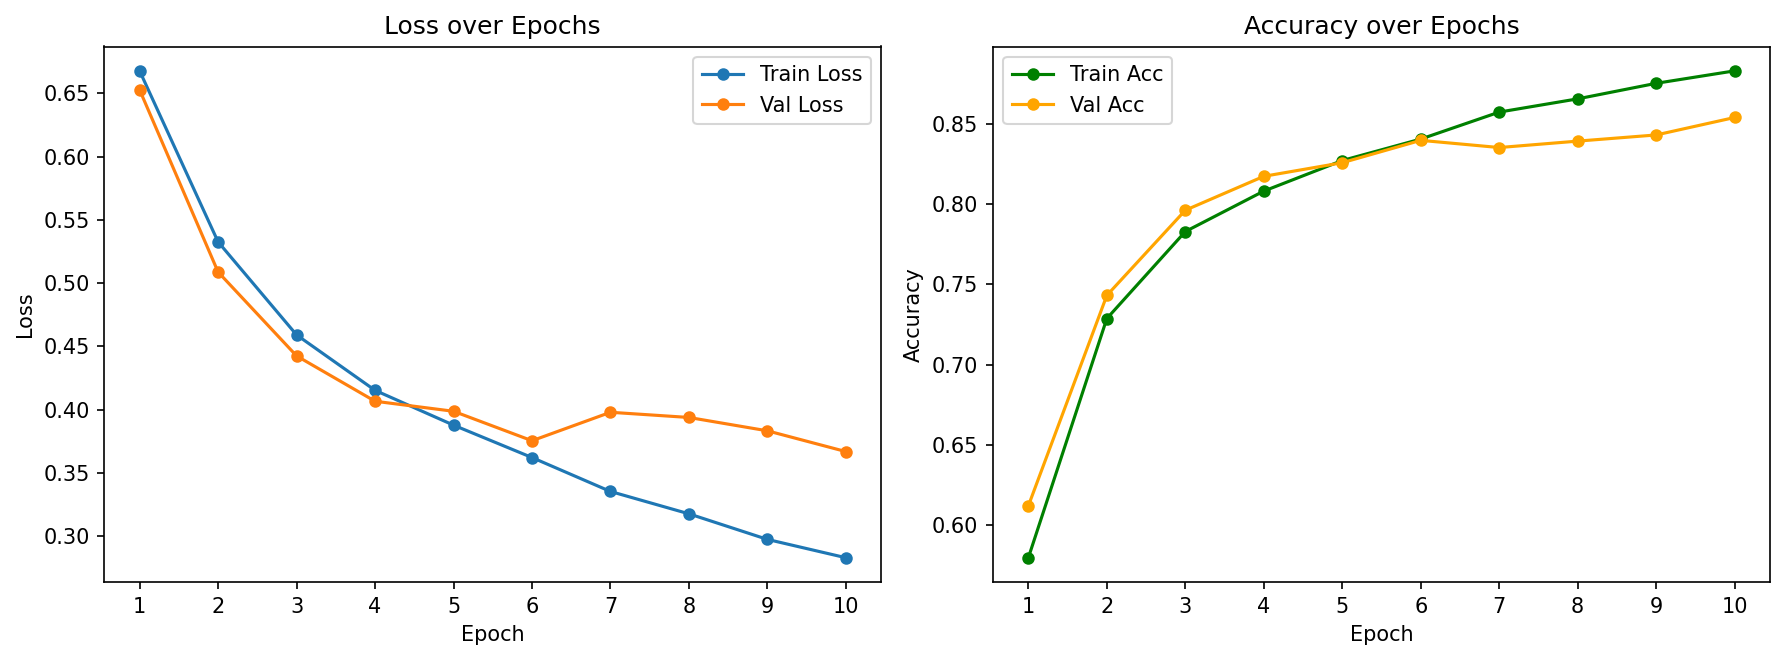

In [91]:
import matplotlib.pyplot as plt

def plot_training_curves(history):
    epochs = range(1, len(history["train_loss"]) + 1)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=150)

    ax1.plot(epochs, history["train_loss"], 'o-', label="Train Loss", color="#1f77b4", linewidth=1.5, markersize=5)
    ax1.plot(epochs, history["val_loss"], 'o-', label="Val Loss", color="#ff7f0e", linewidth=1.5, markersize=5)
    ax1.set_title("Loss over Epochs", fontsize=12)
    ax1.set_xlabel("Epoch", fontsize=10)
    ax1.set_ylabel("Loss", fontsize=10)
    ax1.set_xticks(epochs)
    ax1.legend(loc="upper right", fontsize=10)

    ax2.plot(epochs, history["train_acc"], 'o-', label="Train Acc", color="green", linewidth=1.5, markersize=5)
    ax2.plot(epochs, history["val_acc"], 'o-', label="Val Acc", color="orange", linewidth=1.5, markersize=5)
    ax2.set_title("Accuracy over Epochs", fontsize=12)
    ax2.set_xlabel("Epoch", fontsize=10)
    ax2.set_ylabel("Accuracy", fontsize=10)
    ax2.set_xticks(epochs)
    ax2.legend(loc="upper left", fontsize=10)

    plt.tight_layout()
    
    plt.savefig("transformer_training_curves.png", dpi=300, bbox_inches="tight")
    plt.show()

plot_training_curves(history)